# 01 - Minh chứng Dataset và DSP

Notebook phục vụ Q01-Q07 và Q59-Q65. Trọng tâm là cách chống leakage, vai trò Playback, lý do không dùng silence làm nhãn và quá trình từ PCM16 đến tensor C4 `40×129×1`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown

def find_repo_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / 'Defense_Package').is_dir():
            return path
    raise FileNotFoundError('Không tìm thấy repository root chứa Defense_Package')

ROOT = find_repo_root()
EVIDENCE = ROOT / 'Defense_Package' / '02_Defense_Evidence'

def show_image(relative_path, width=1100):
    path = EVIDENCE / relative_path
    if not path.exists():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))

print('ROOT =', ROOT)
print('EVIDENCE =', EVIDENCE)

ROOT = d:\NCKH_2026\NCKH_2026_AIOT
EVIDENCE = d:\NCKH_2026\NCKH_2026_AIOT\Defense_Package\02_Defense_Evidence


## 1. Dataset split và chống leakage - Q01, Q59, Q60

- Core chia theo **Patient ID**.
- Playback chia theo **WAV nguồn**.
- Environment chia theo **Session ID**.

Không chia ngẫu nhiên từng file vì các bản ghi liên quan có thể lọt sang hai tập và làm Accuracy lạc quan giả.

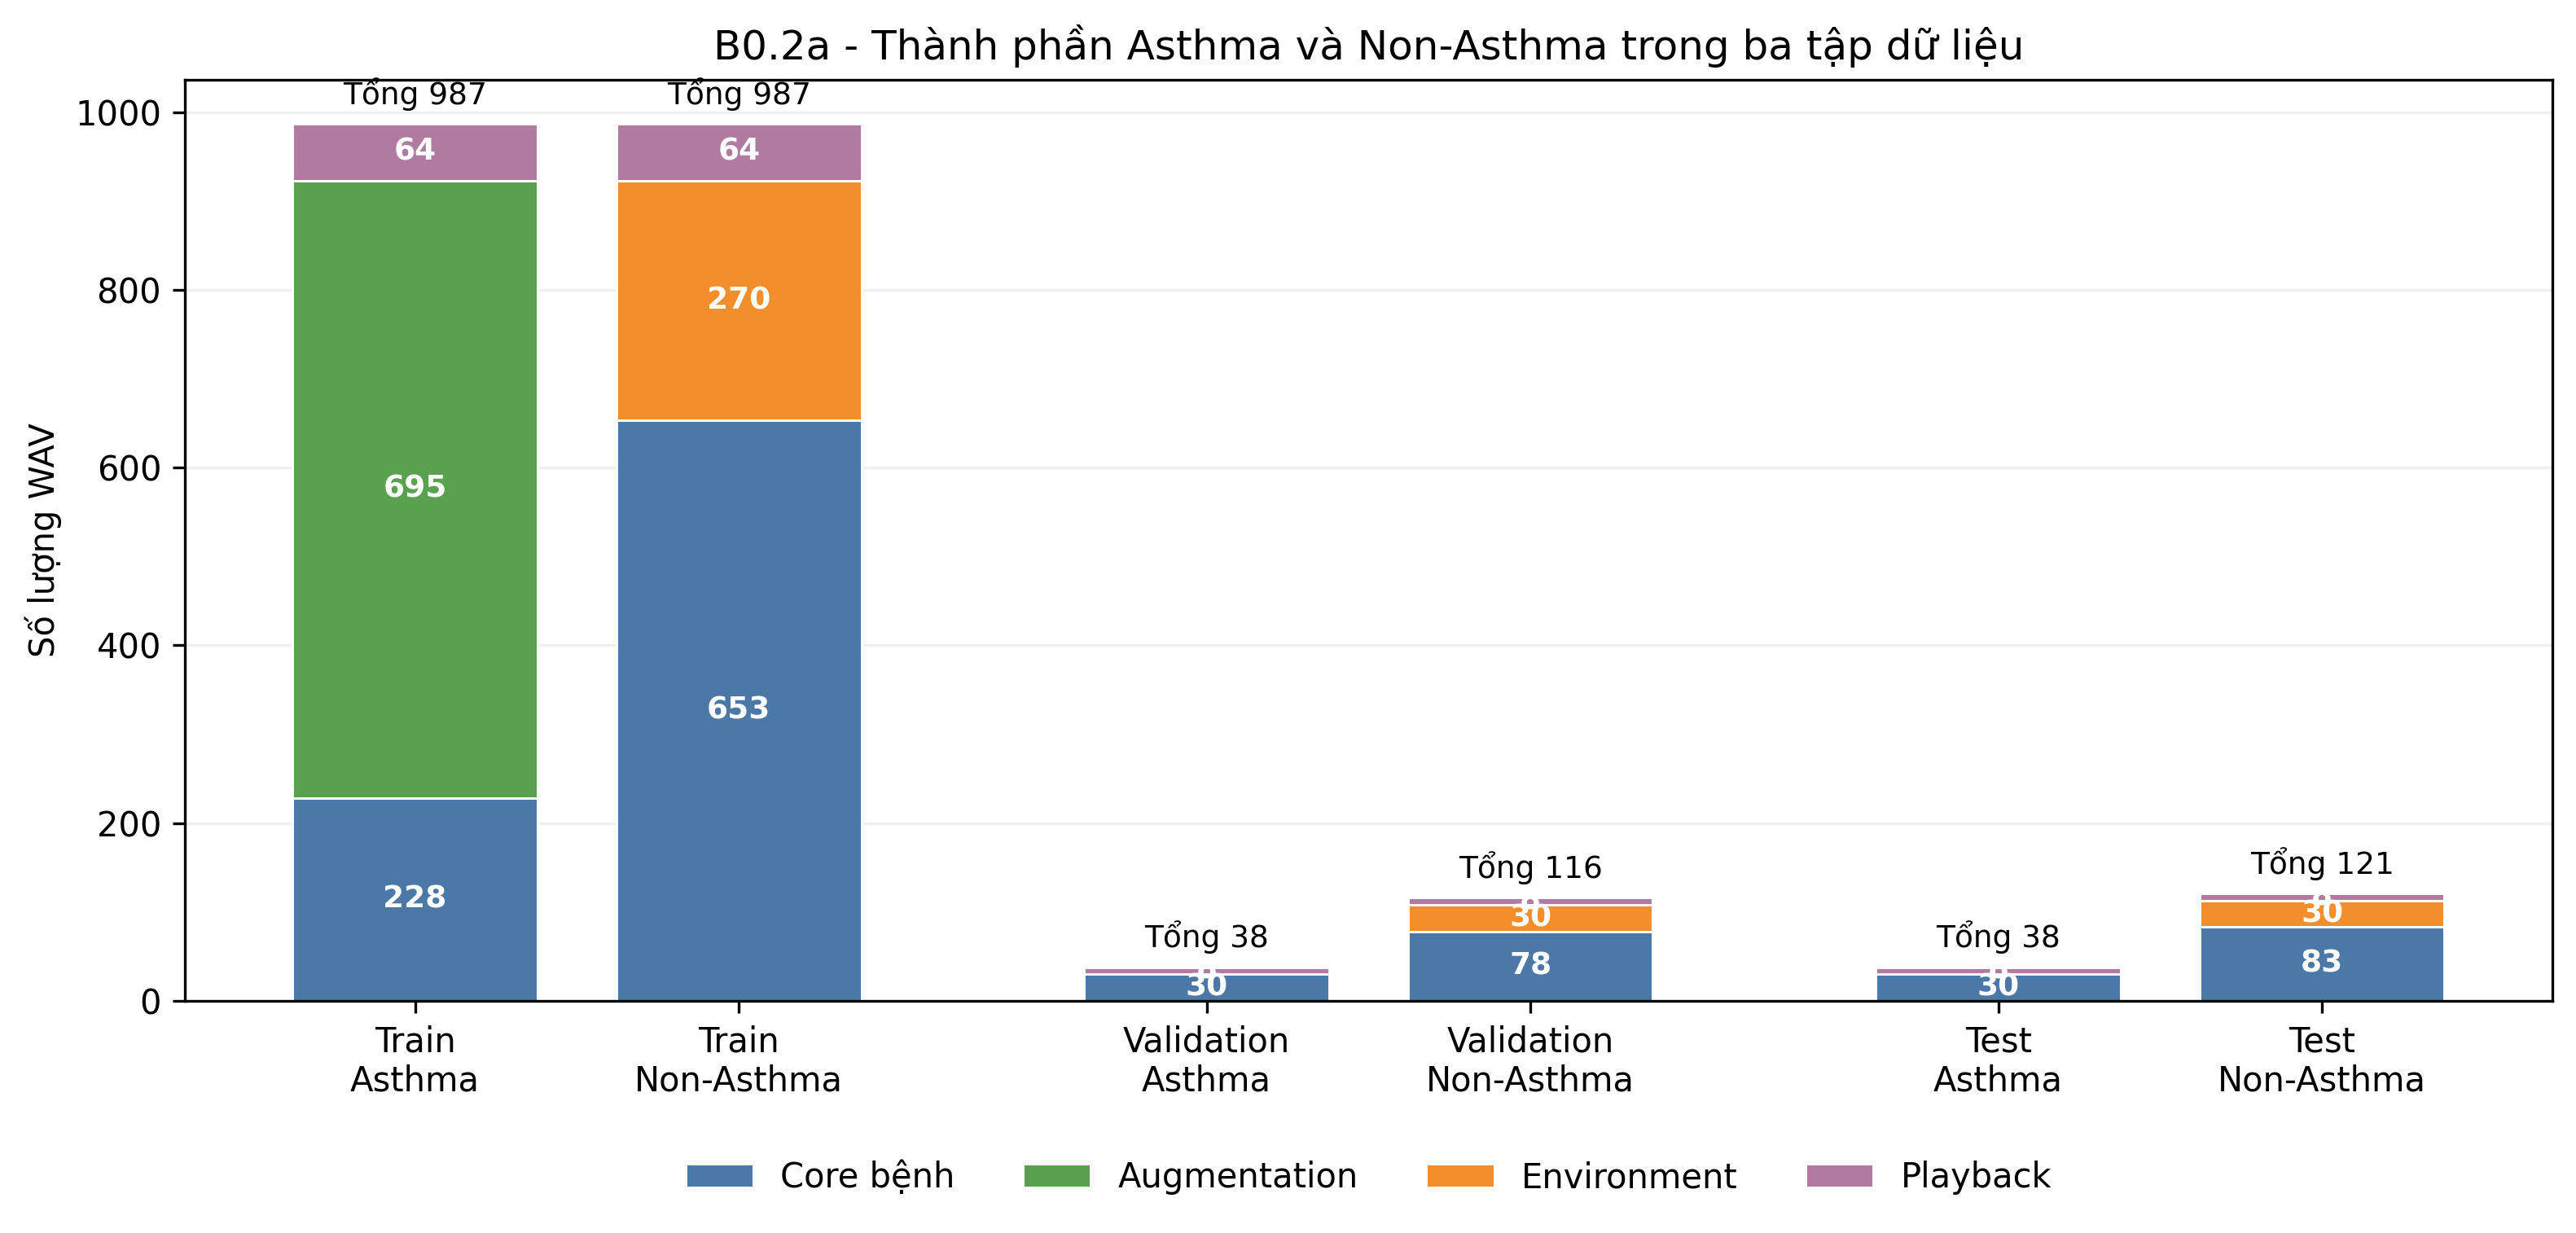

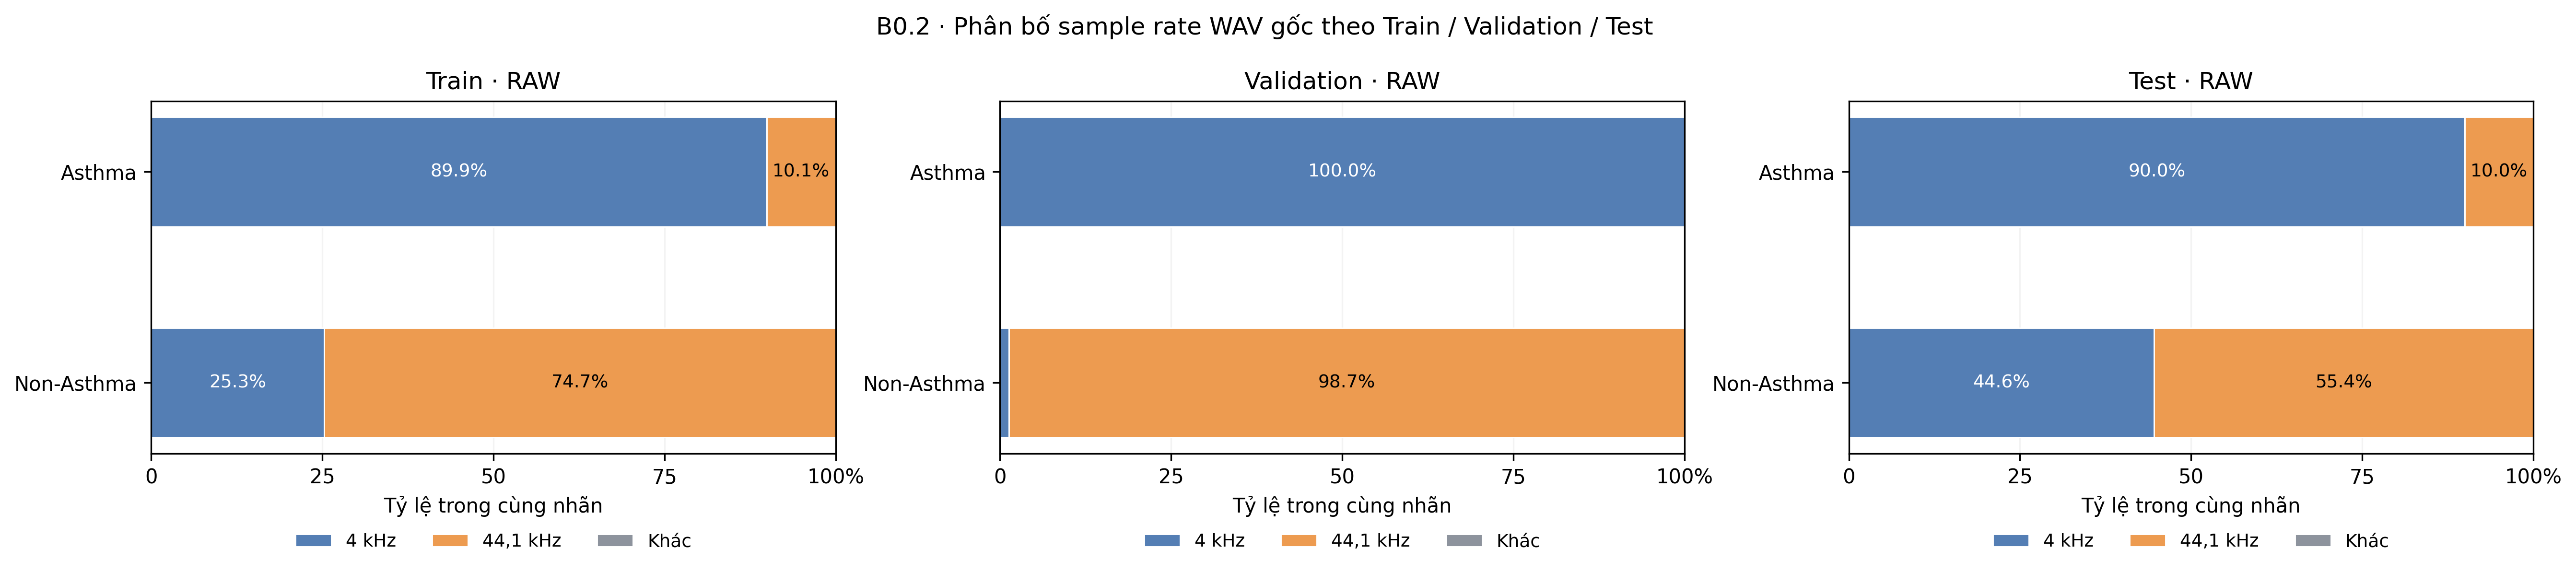

In [2]:
show_image('figures/01_Dataset/01_Label_Source_Composition.png')
show_image('figures/01_Dataset/02_Sample_Rate_Train_Val_Test.png')

## 2. Playback hay chỉ WAV gốc? - Q61

Playback mô phỏng domain loa → không gian → INMP441. Kết quả ablation là bằng chứng hỗn hợp, do đó lập luận đúng là Playback **tăng độ phủ domain**, không phải luôn làm mọi metric tốt hơn.

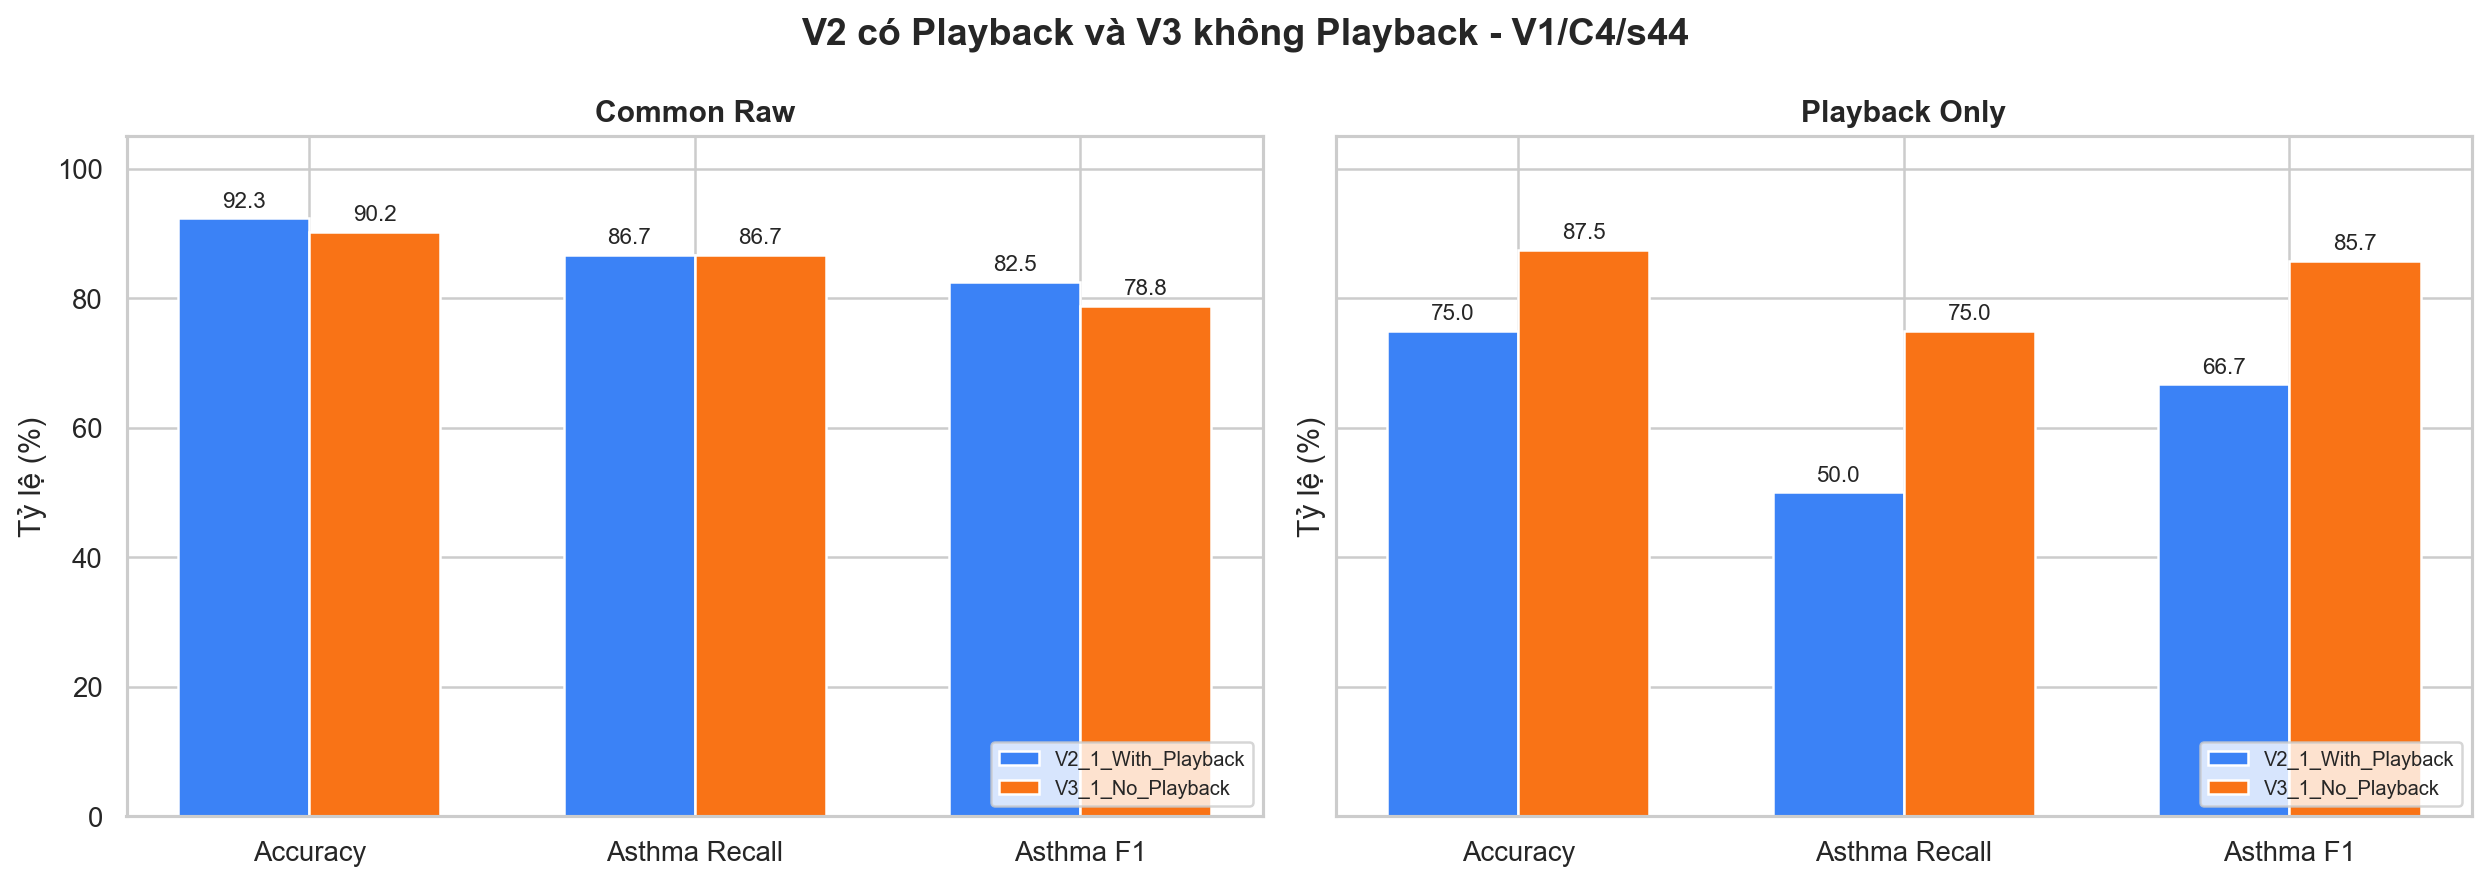

,test_name,model,sample_count,asthma_count,non_asthma_count,accuracy,asthma_precision,asthma_recall,asthma_f1,non_asthma_precision,non_asthma_recall,non_asthma_f1,true_asthma_pred_asthma,true_asthma_pred_non_asthma,true_non_asthma_pred_asthma,true_non_asthma_pred_non_asthma
0,common_raw,V2_1_With_Playback,143,30,113,0.923077,0.787879,0.866667,0.825397,0.963636,0.938053,0.950673,26,4,7,106
1,common_raw,V3_1_No_Playback,143,30,113,0.902098,0.722222,0.866667,0.787879,0.962617,0.911504,0.936364,26,4,10,103
2,playback_only,V2_1_With_Playback,16,8,8,0.750000,1.000000,0.500000,0.666667,0.666667,1.000000,0.800000,4,4,0,8
3,playback_only,V3_1_No_Playback,16,8,8,0.875000,1.000000,0.750000,0.857143,0.800000,1.000000,0.888889,6,2,0,8


In [3]:
show_image('figures/01_Dataset/03_Playback_Ablation_V2_V3.png')
playback = pd.read_csv(EVIDENCE / 'data/Playback_Ablation_Metrics.csv')
display(playback)

## 3. Vì sao silence không phải Non-Asthma? - Q62

Silence là cửa sổ **không đủ điều kiện suy luận**. Nếu gán silence vào Non-Asthma, model có thể học lối tắt theo năng lượng. VAD và Quality Gate loại trường hợp này trước model.

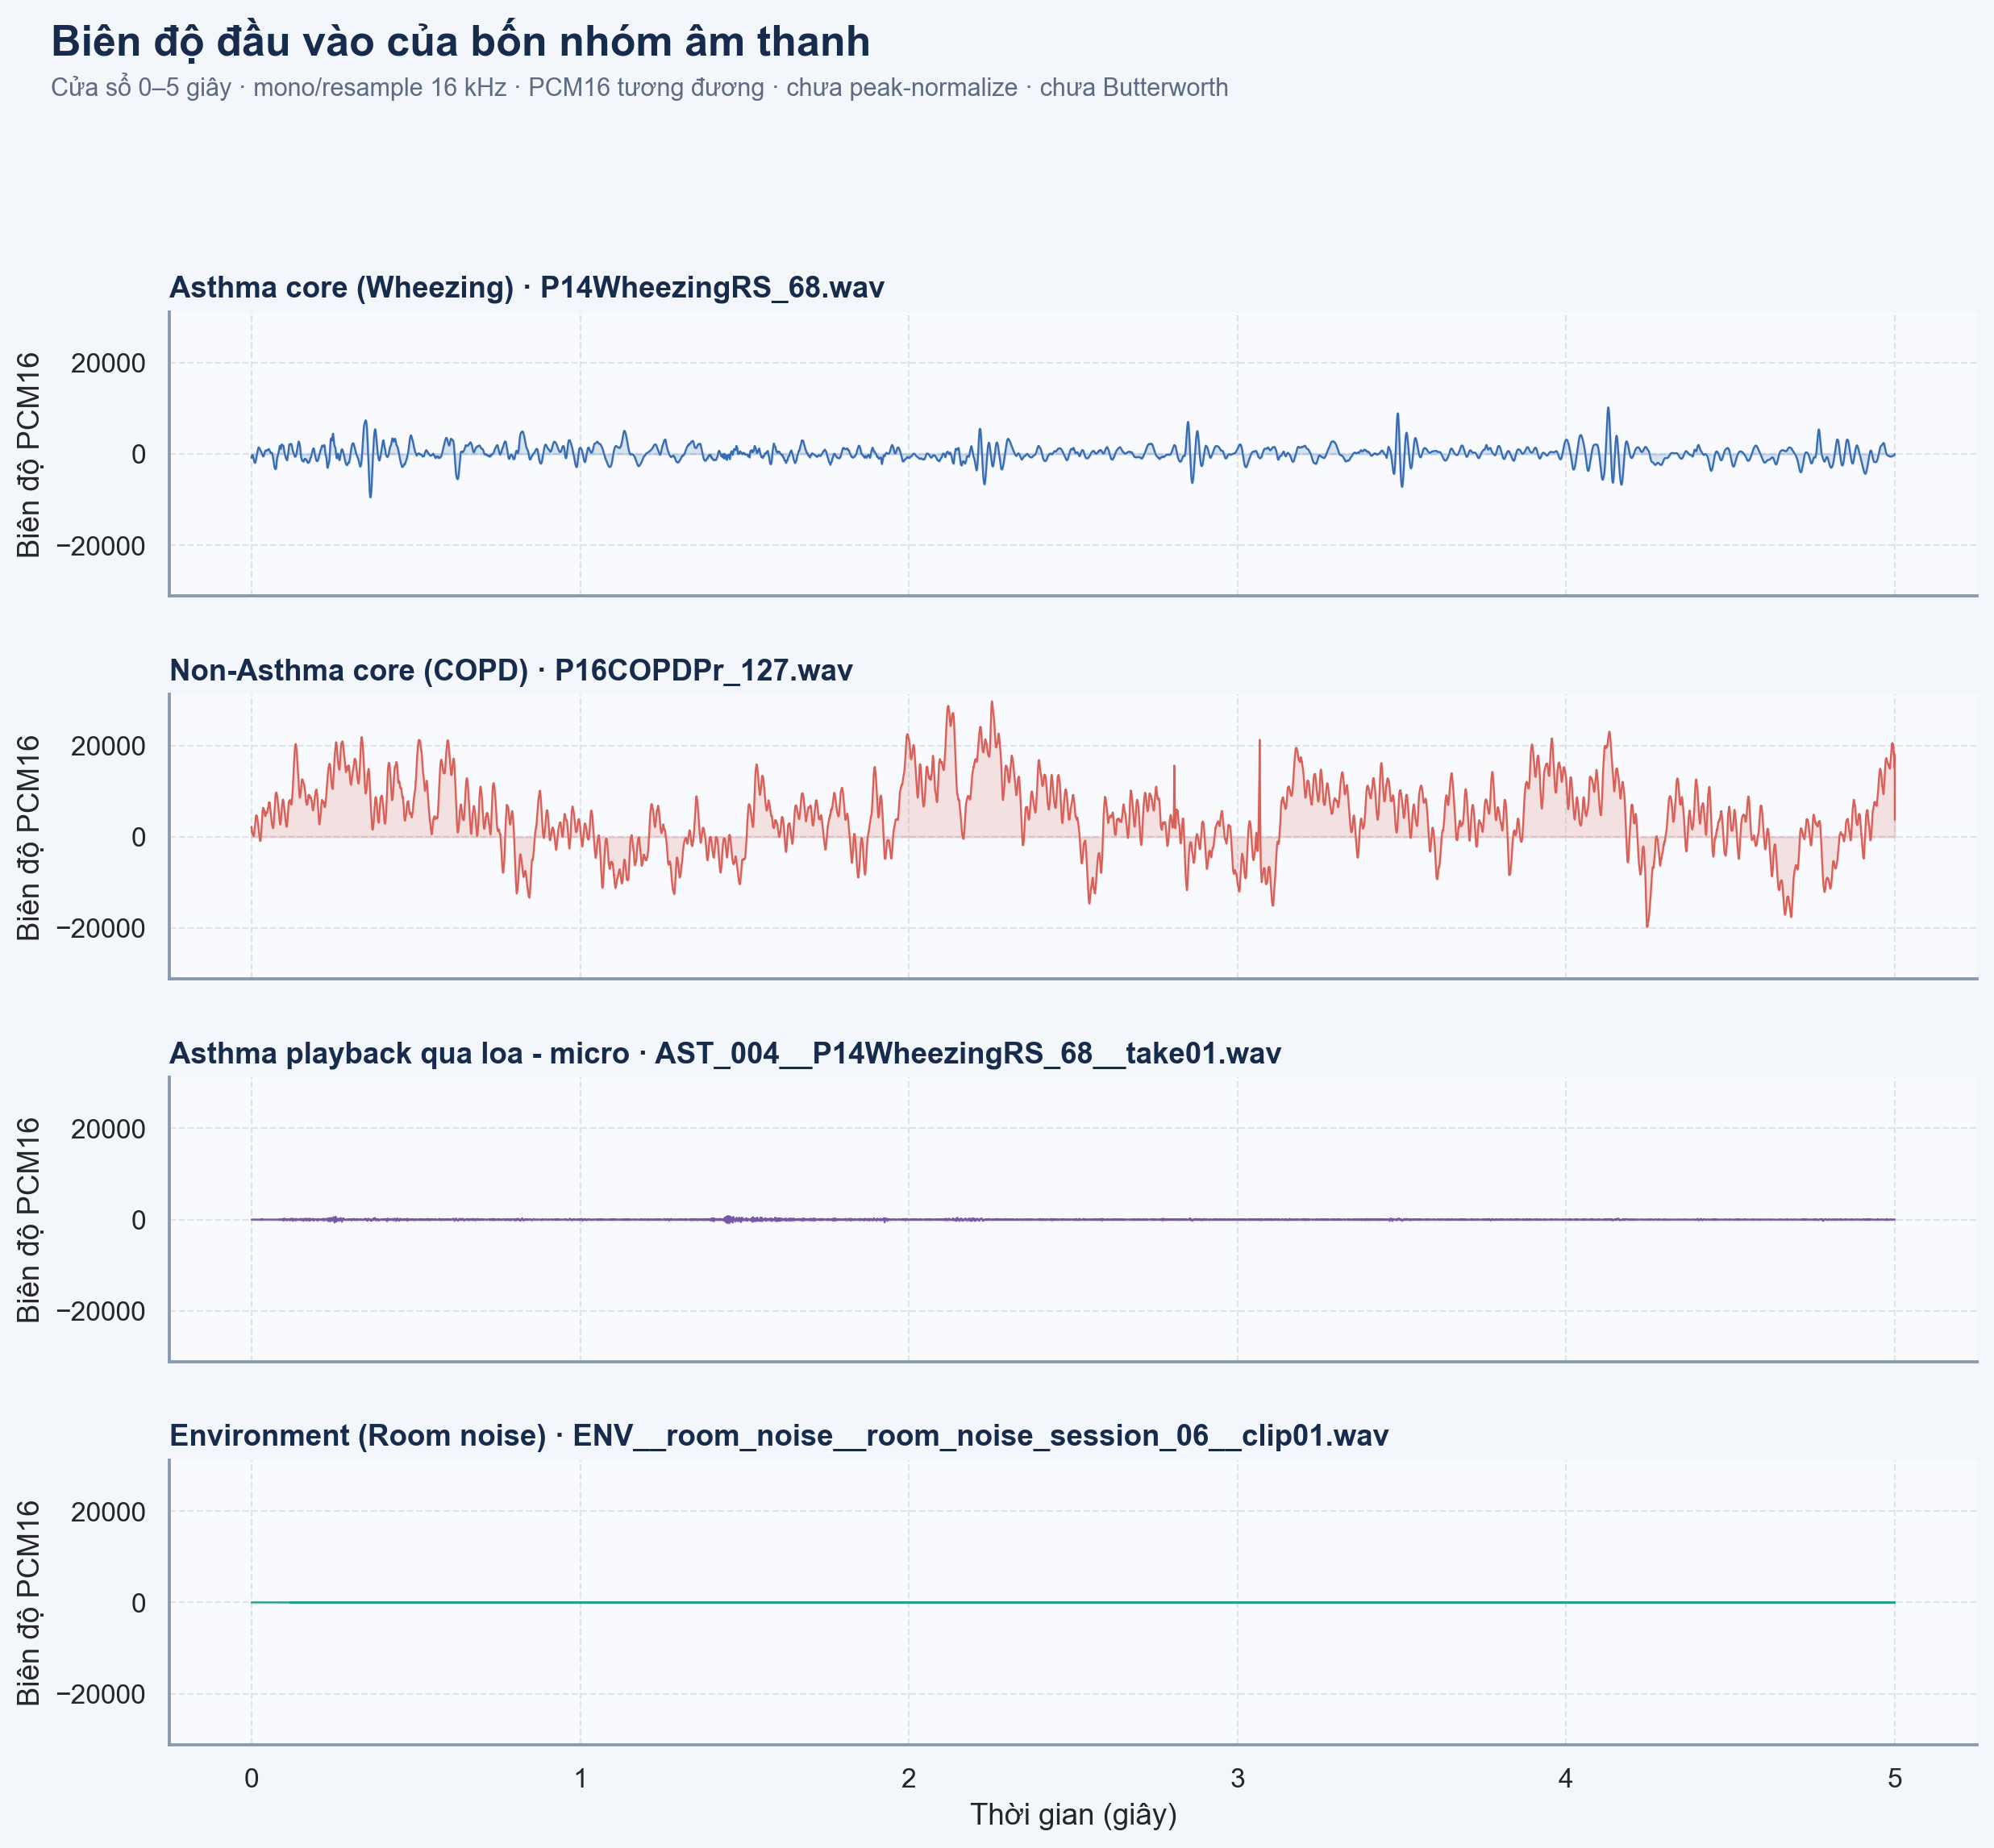

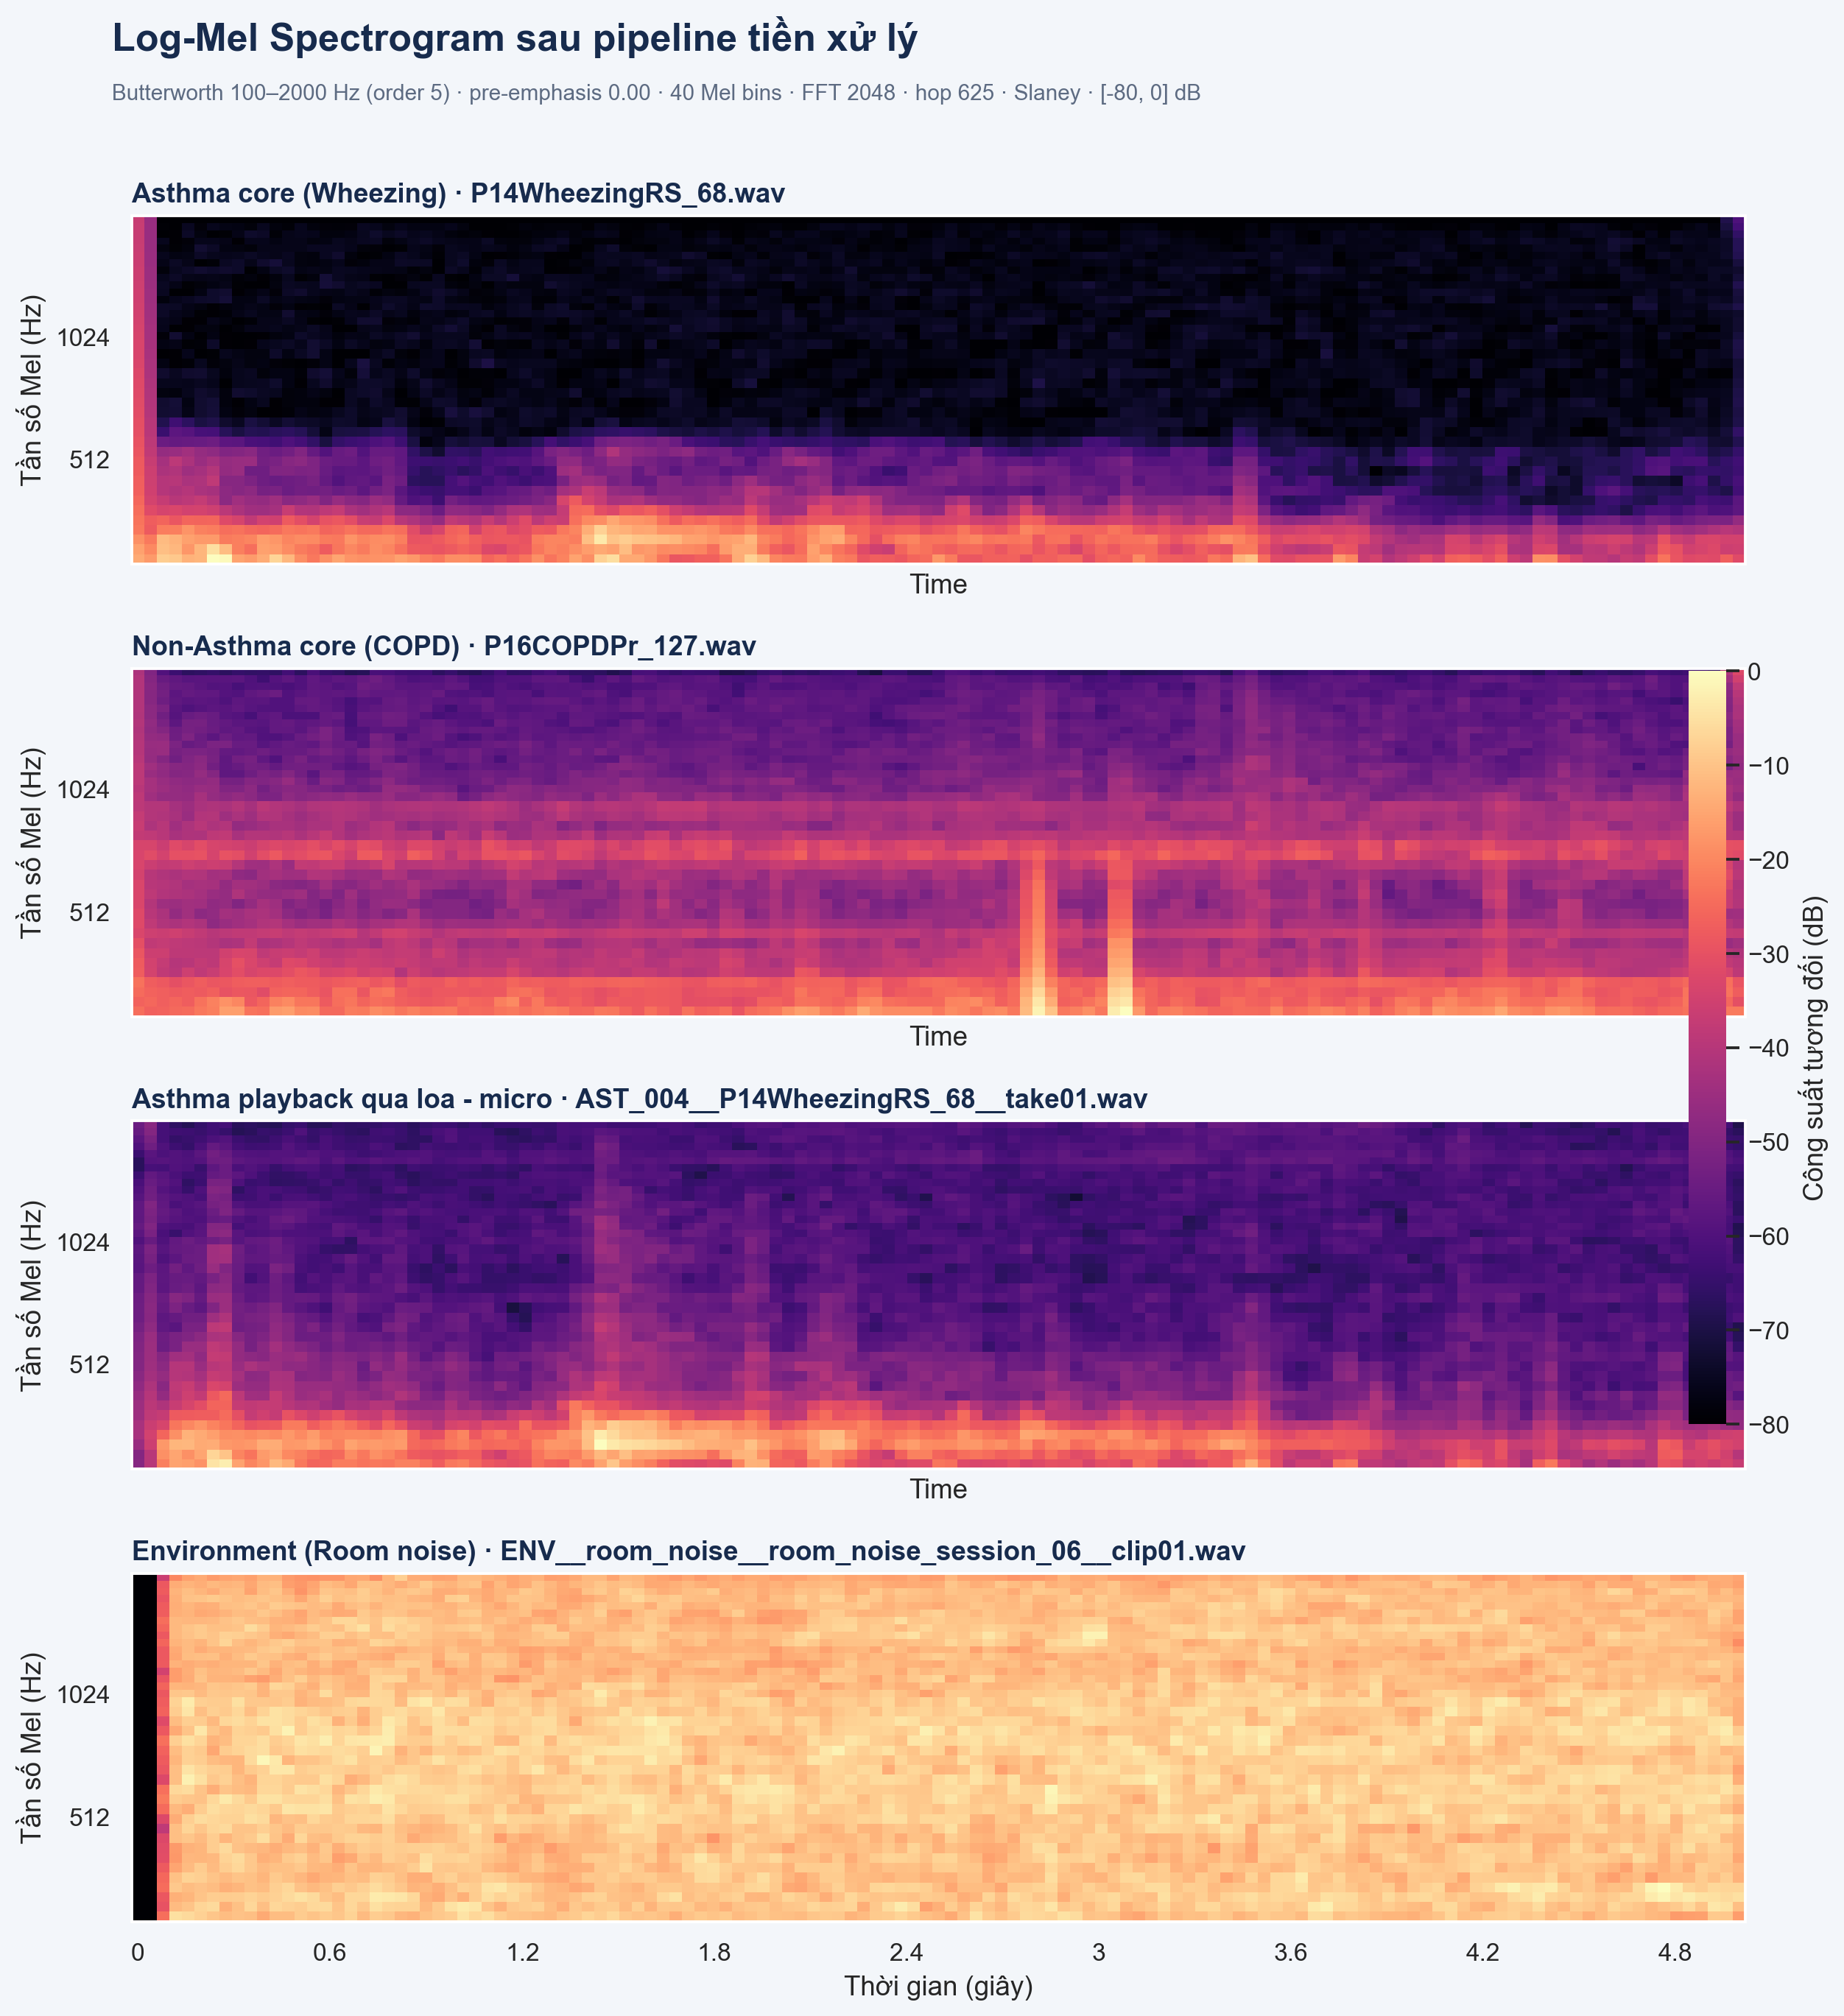

In [4]:
show_image('figures/02_DSP/01_PCM16_Waveforms.png')
show_image('figures/02_DSP/02_LogMel_C4.png')

## 4. Butterworth 100-2000 Hz và cửa sổ 5 giây - Q04, Q63

Dải thông tập trung vùng khảo sát hô hấp, còn cửa sổ 5 giây cân bằng ngữ cảnh, độ trễ và bộ nhớ. Đây là điểm làm việc đã kiểm định; không gọi là tối ưu tuyệt đối nếu chưa có ablation đầy đủ theo độ dài cửa sổ.

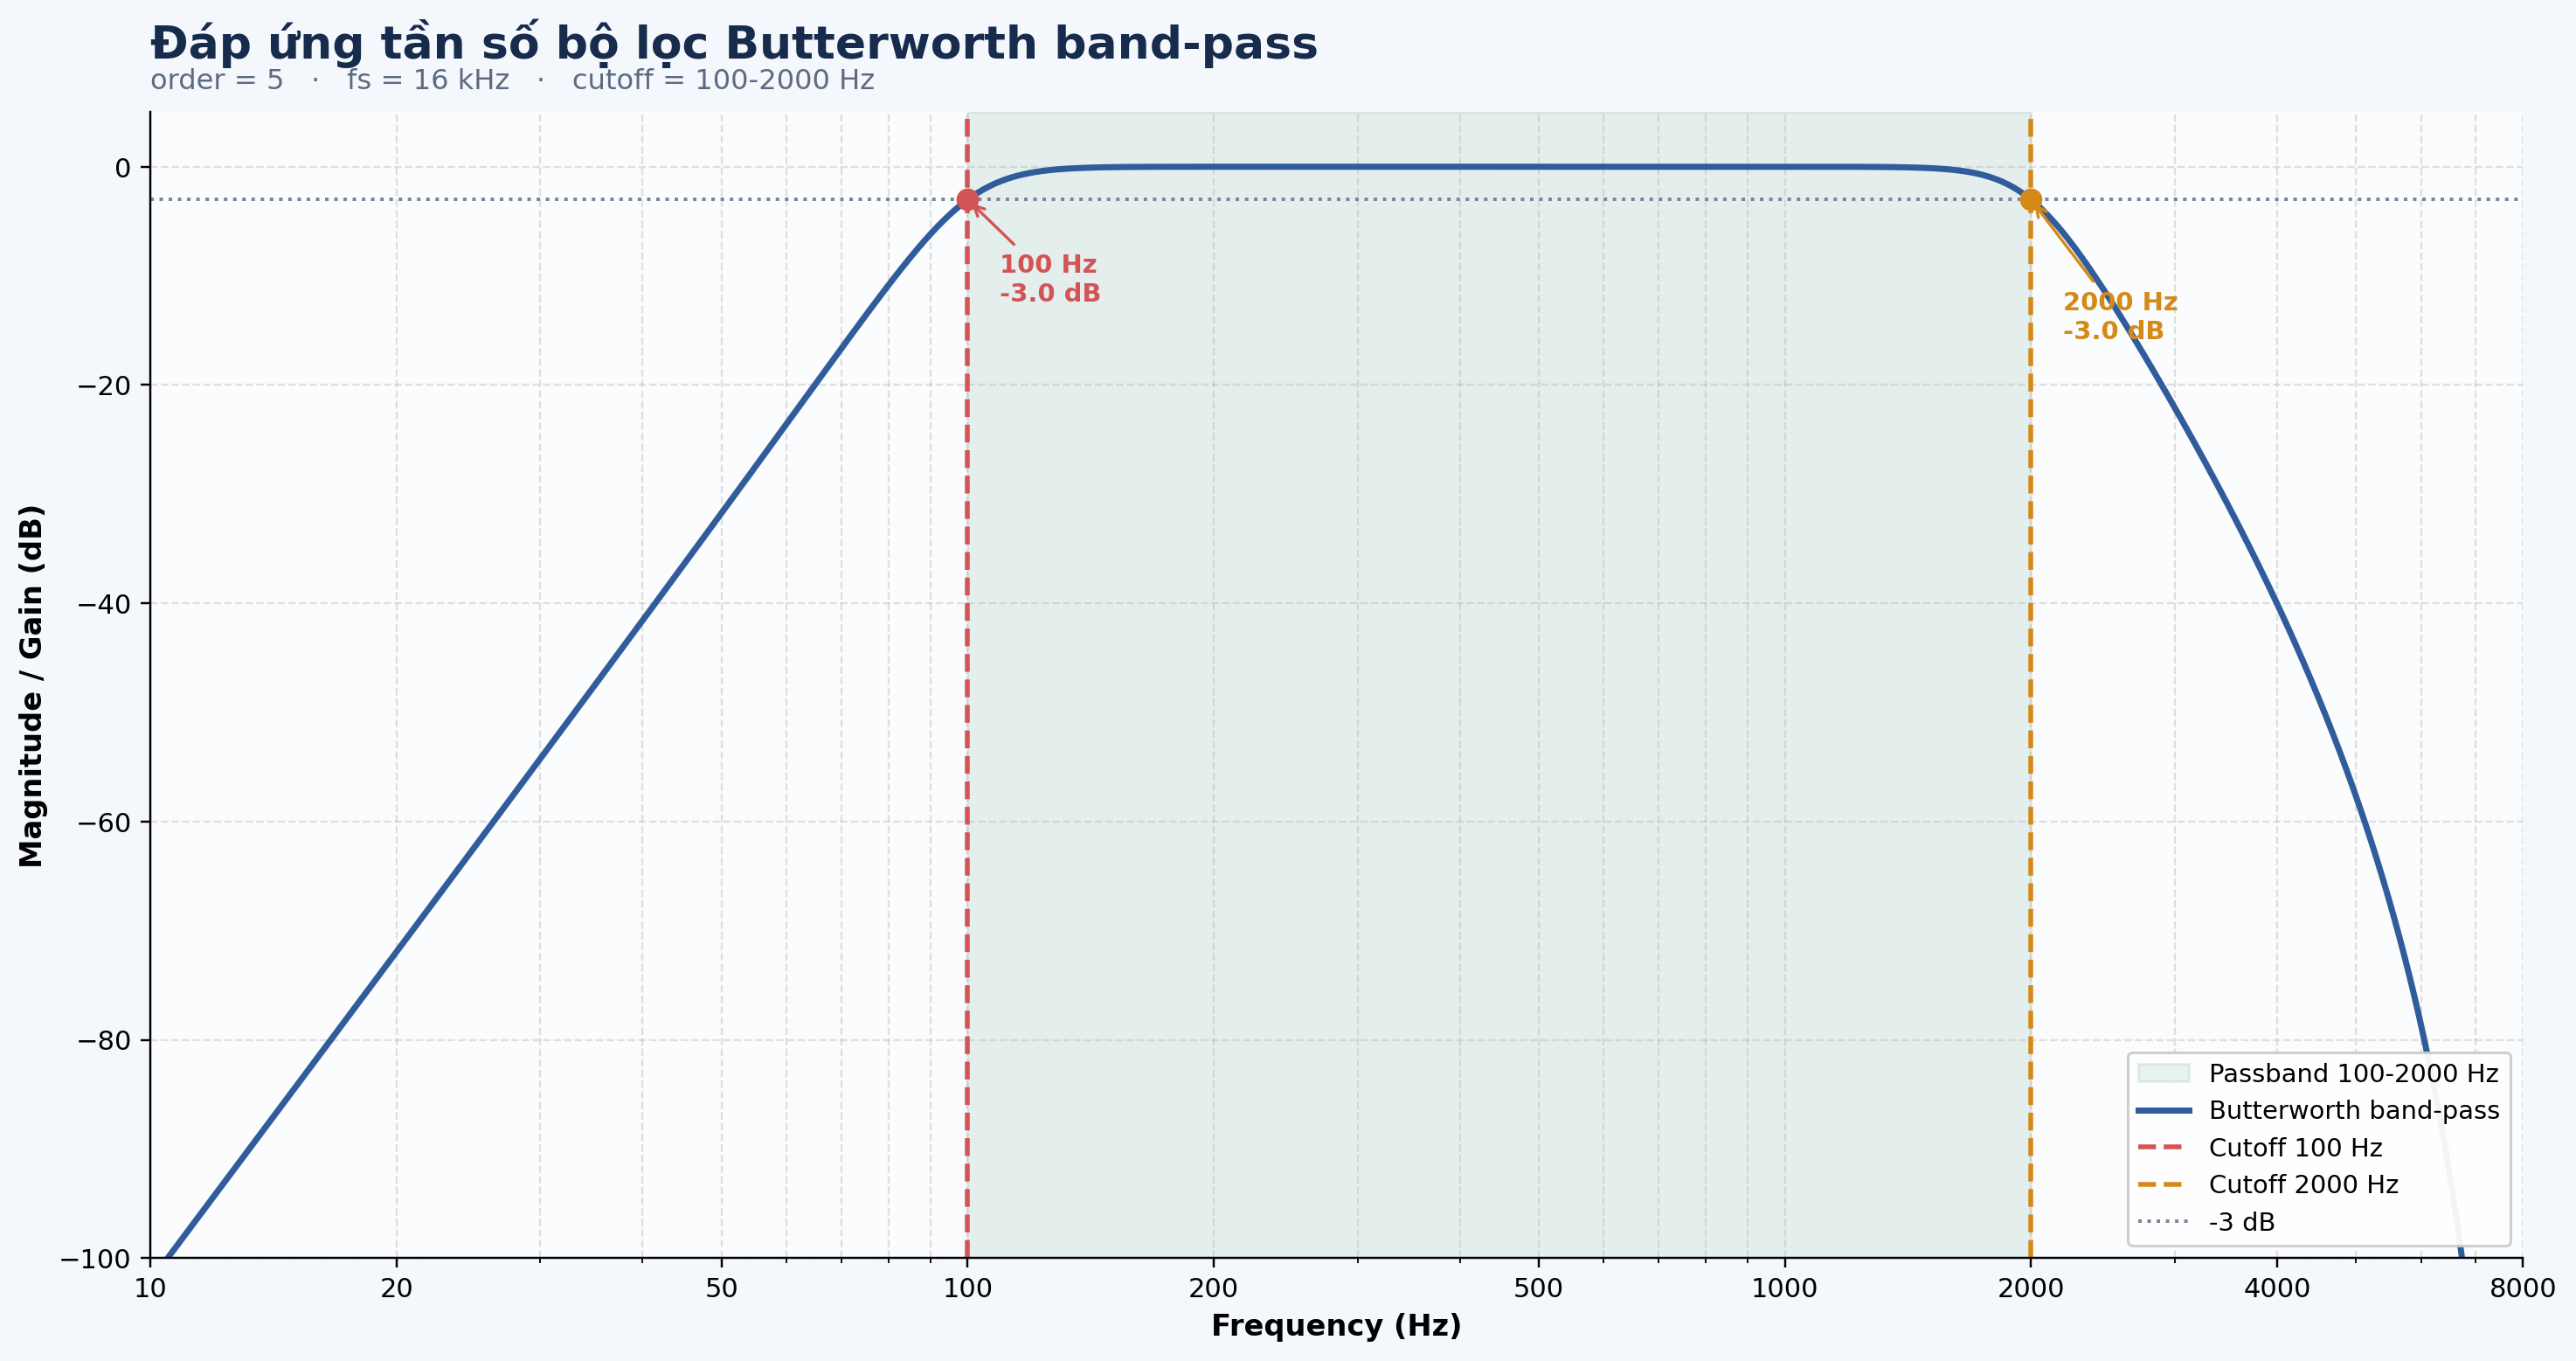

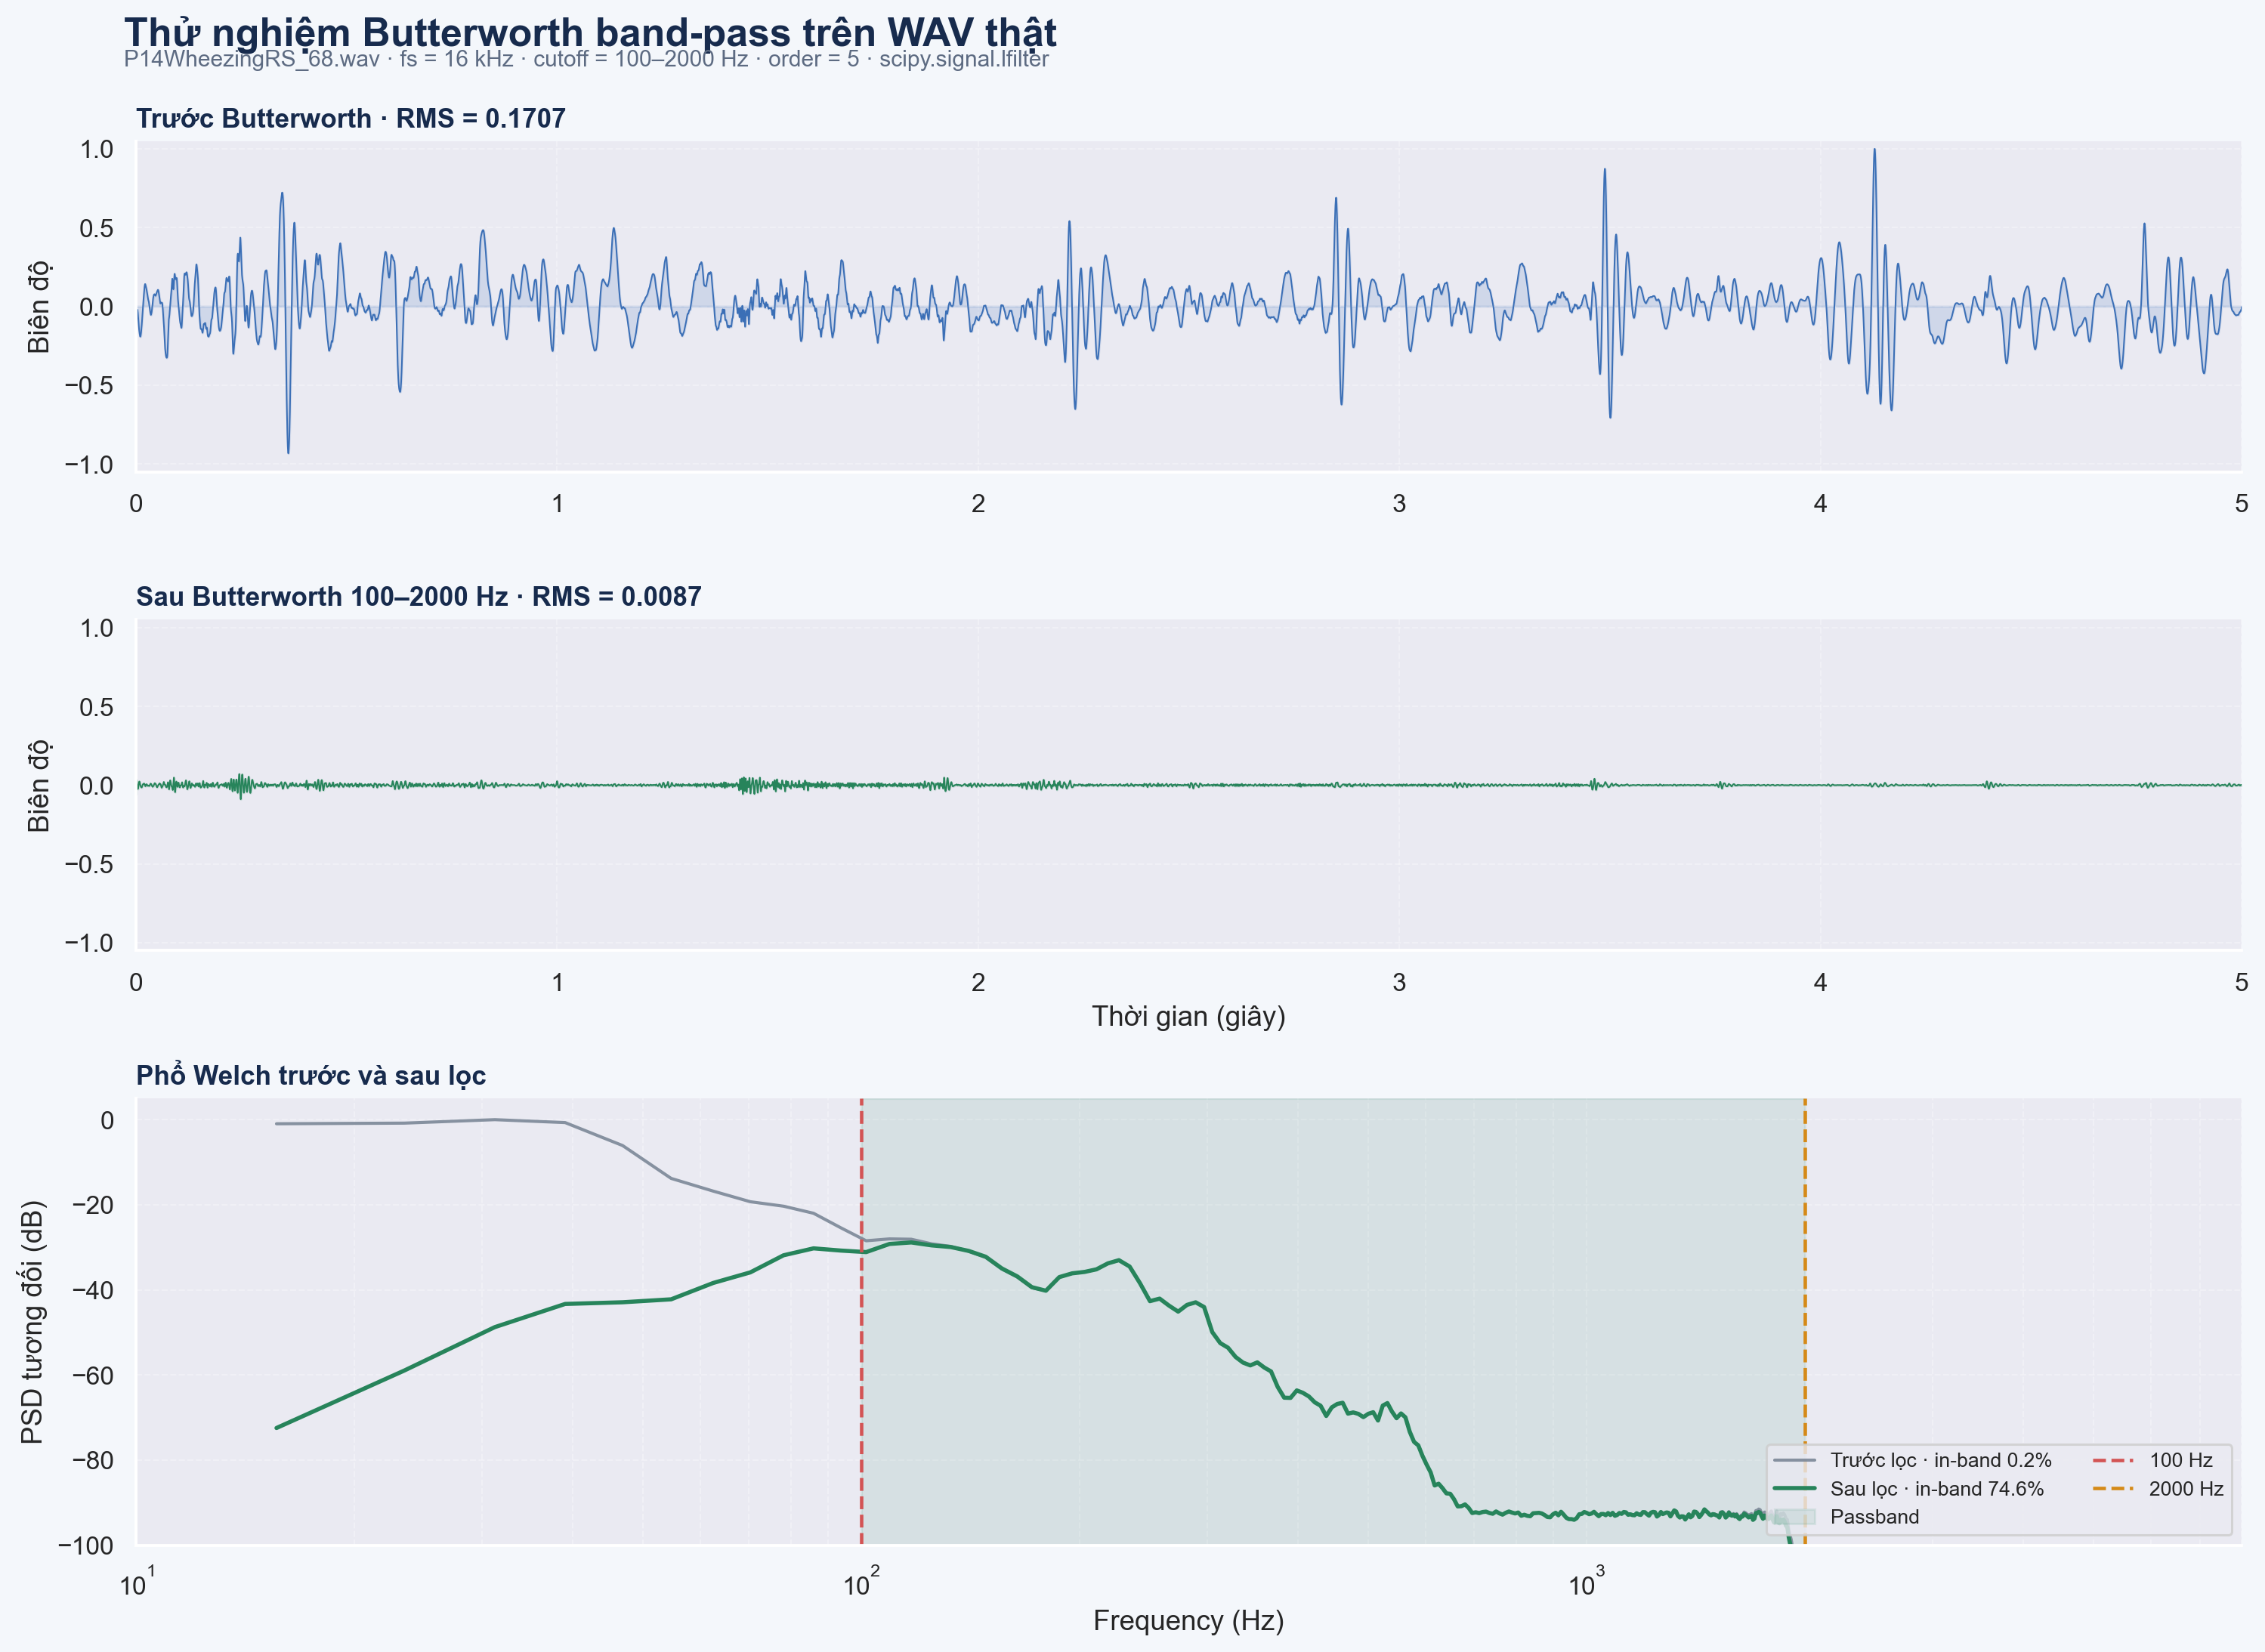

In [5]:
show_image('figures/02_DSP/03_Butterworth_Response.png')
show_image('figures/02_DSP/04_Butterworth_Before_After.png')

## 5. Vì sao Log-Mel và C4? - Q03, Q05-Q07, Q64-Q65

C4 dùng `pre-emphasis=0`, `n_mels=40`, `n_fft=2048`, `hop=625`. OFAT dùng để giải thích từng yếu tố; factorial dùng để kiểm tra tương tác. Vì vậy không ghép cơ học các winner riêng lẻ.

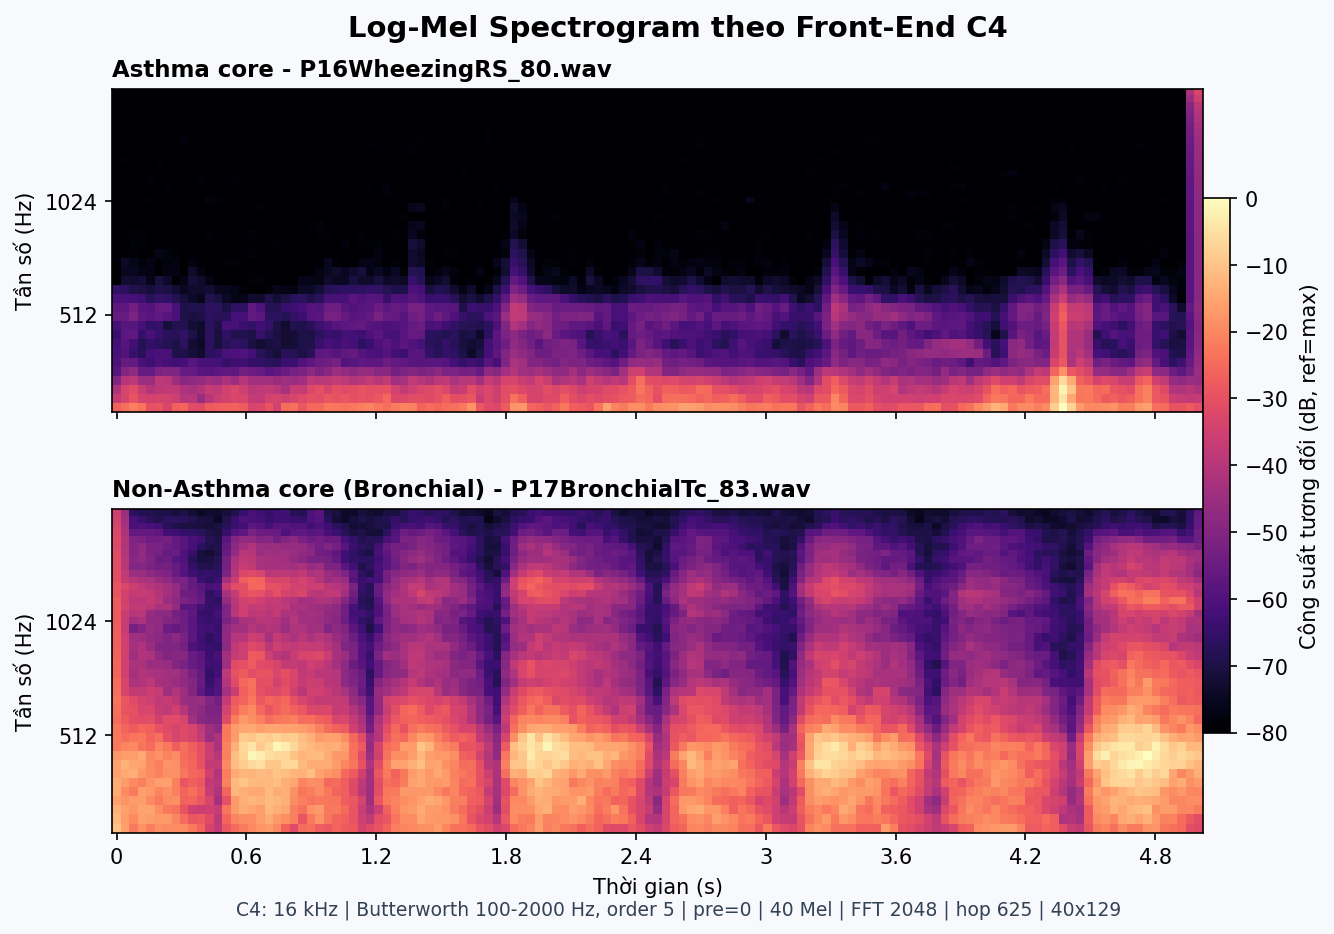

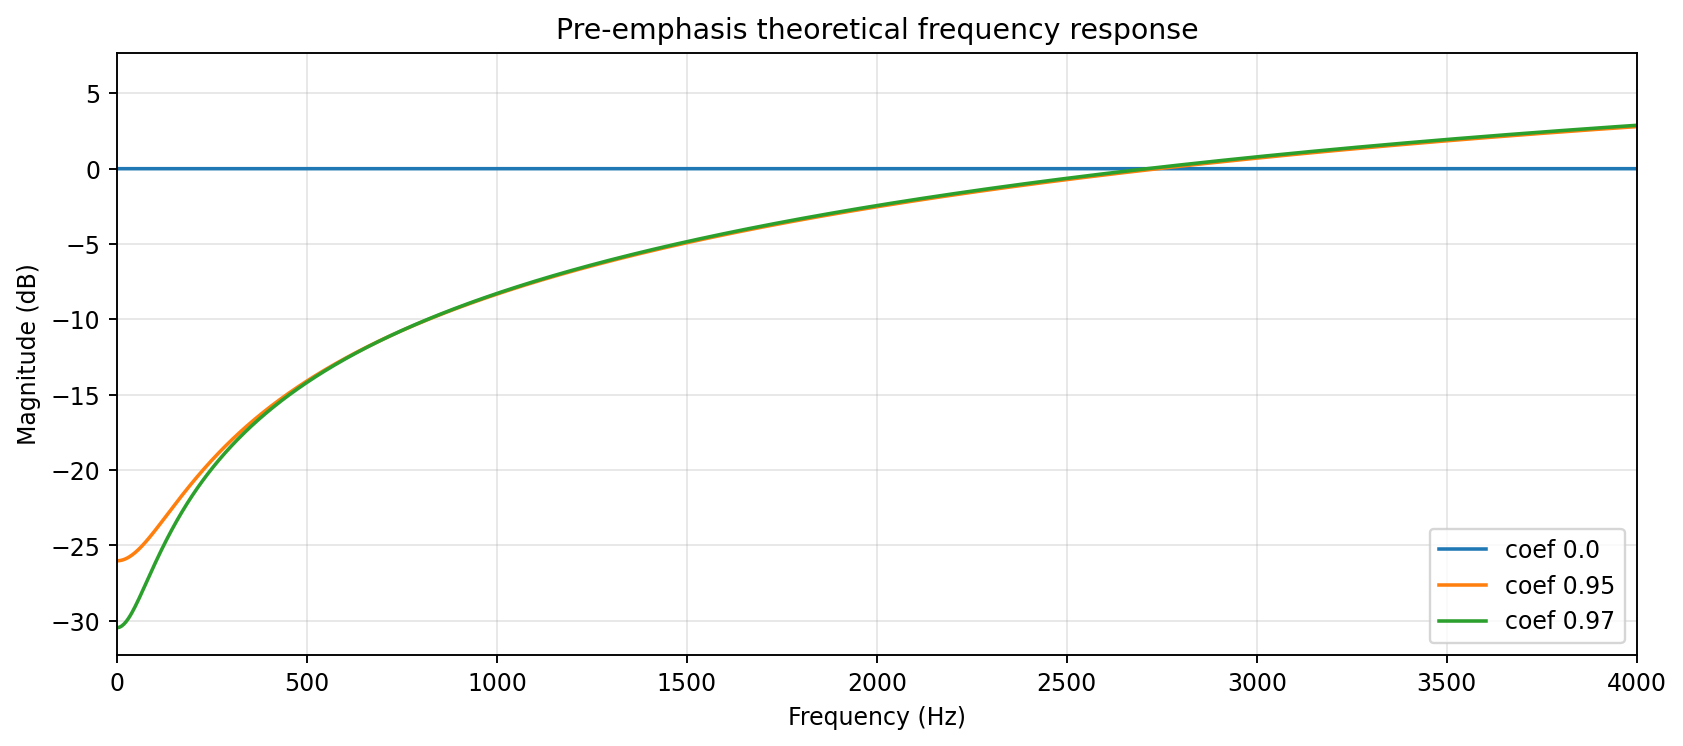

In [6]:
show_image('figures/02_DSP/05_C4_LogMel_Disease_Comparison.png')
pre = ROOT / 'Experiments_Benchmarking/Patient_Node/Frontend_Benchmarking/results/A_scientific_frontend_evidence/figures/04_pre_emphasis_response.png'
if pre.exists():
    display(Image(filename=str(pre), width=1000))
else:
    print('Không tìm thấy hình pre-emphasis:', pre)

## 6. Câu chốt khi trình bày

> Dataset được chia theo đơn vị độc lập để chống leakage. Playback được dùng để phủ domain phần cứng. Silence được VAD/Quality Gate xử lý thay vì biến thành nhãn. C4 là kết quả của OFAT + factorial nhiều seed, sau đó mới chuyển sang lựa chọn model và lượng tử.

Đáp án chi tiết: [Q59](../01_Committee_QnA/Answers/Q59.md), [Q61](../01_Committee_QnA/Answers/Q61.md), [Q64](../01_Committee_QnA/Answers/Q64.md), [Q65](../01_Committee_QnA/Answers/Q65.md).